---
title: "Hierarchical Modeling with PyMC" 
author: "Sheng Long"
date: "12/17/25"
abstract: |
    Implemented some hierarchical modelling related examples in *Statistical Rethinking* with `PyMC`. 
keywords: 
    - statistics 
format:
    html:
        code-fold: false
ipynb-shell-interactivity: all
---

:::{.callout-note collapse="true"}
# TLDR

In order to figure out how to actually deploy fitted Bayesian models and integrate with the (broader) community of python users, here's an attempt to work through `PyMC` syntax to figure out how to fit hierarchical Bayesian models using the examples from *Statistical Rethinking*. 

## Biggest change compared to `brms`

Coming from a `brms` background, the first thing to notice about `PyMC` is that a lot of the implied data processing done by `brms` will now require manual code when using `PyMC`. In other words, before one could assume that `brms` will take care of things such as creating dummy variables and index variables when the dataframe specified which columns are categorical vs numerical, in `PyMC`, this step is **manual**. One also needs to do things such reparameterization **manually**. 

:::


We will use the tadpole survival in ponds dataset used in McElreath's *Statistical Rethinking* textbook. The `reedfrogs.csv` is obtained from [here](https://github.com/rmcelreath/rethinking/blob/master/data/reedfrogs.csv). One can follow along the original textbook starting from *Chapter 13.1 Example: Multilevel tadpoles*. 

In [4]:
import pandas as pd
import pymc as pm
import arviz as az
az.style.use("arviz-docgrid")

In [ ]:
# read in data for reedfrogs dataset 
df = pd.read_csv("reedfrogs.csv", delimiter=";")
df.info()
df.head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   density   48 non-null     int64  
 1   pred      48 non-null     object 
 2   size      48 non-null     object 
 3   surv      48 non-null     int64  
 4   propsurv  48 non-null     float64
dtypes: float64(1), int64(2), object(2)
memory usage: 2.0+ KB


,density,pred,size,surv,propsurv
0,10,no,big,9,0.9
1,10,no,big,10,1.0
2,10,no,big,7,0.7
3,10,no,big,10,1.0
4,10,no,small,9,0.9


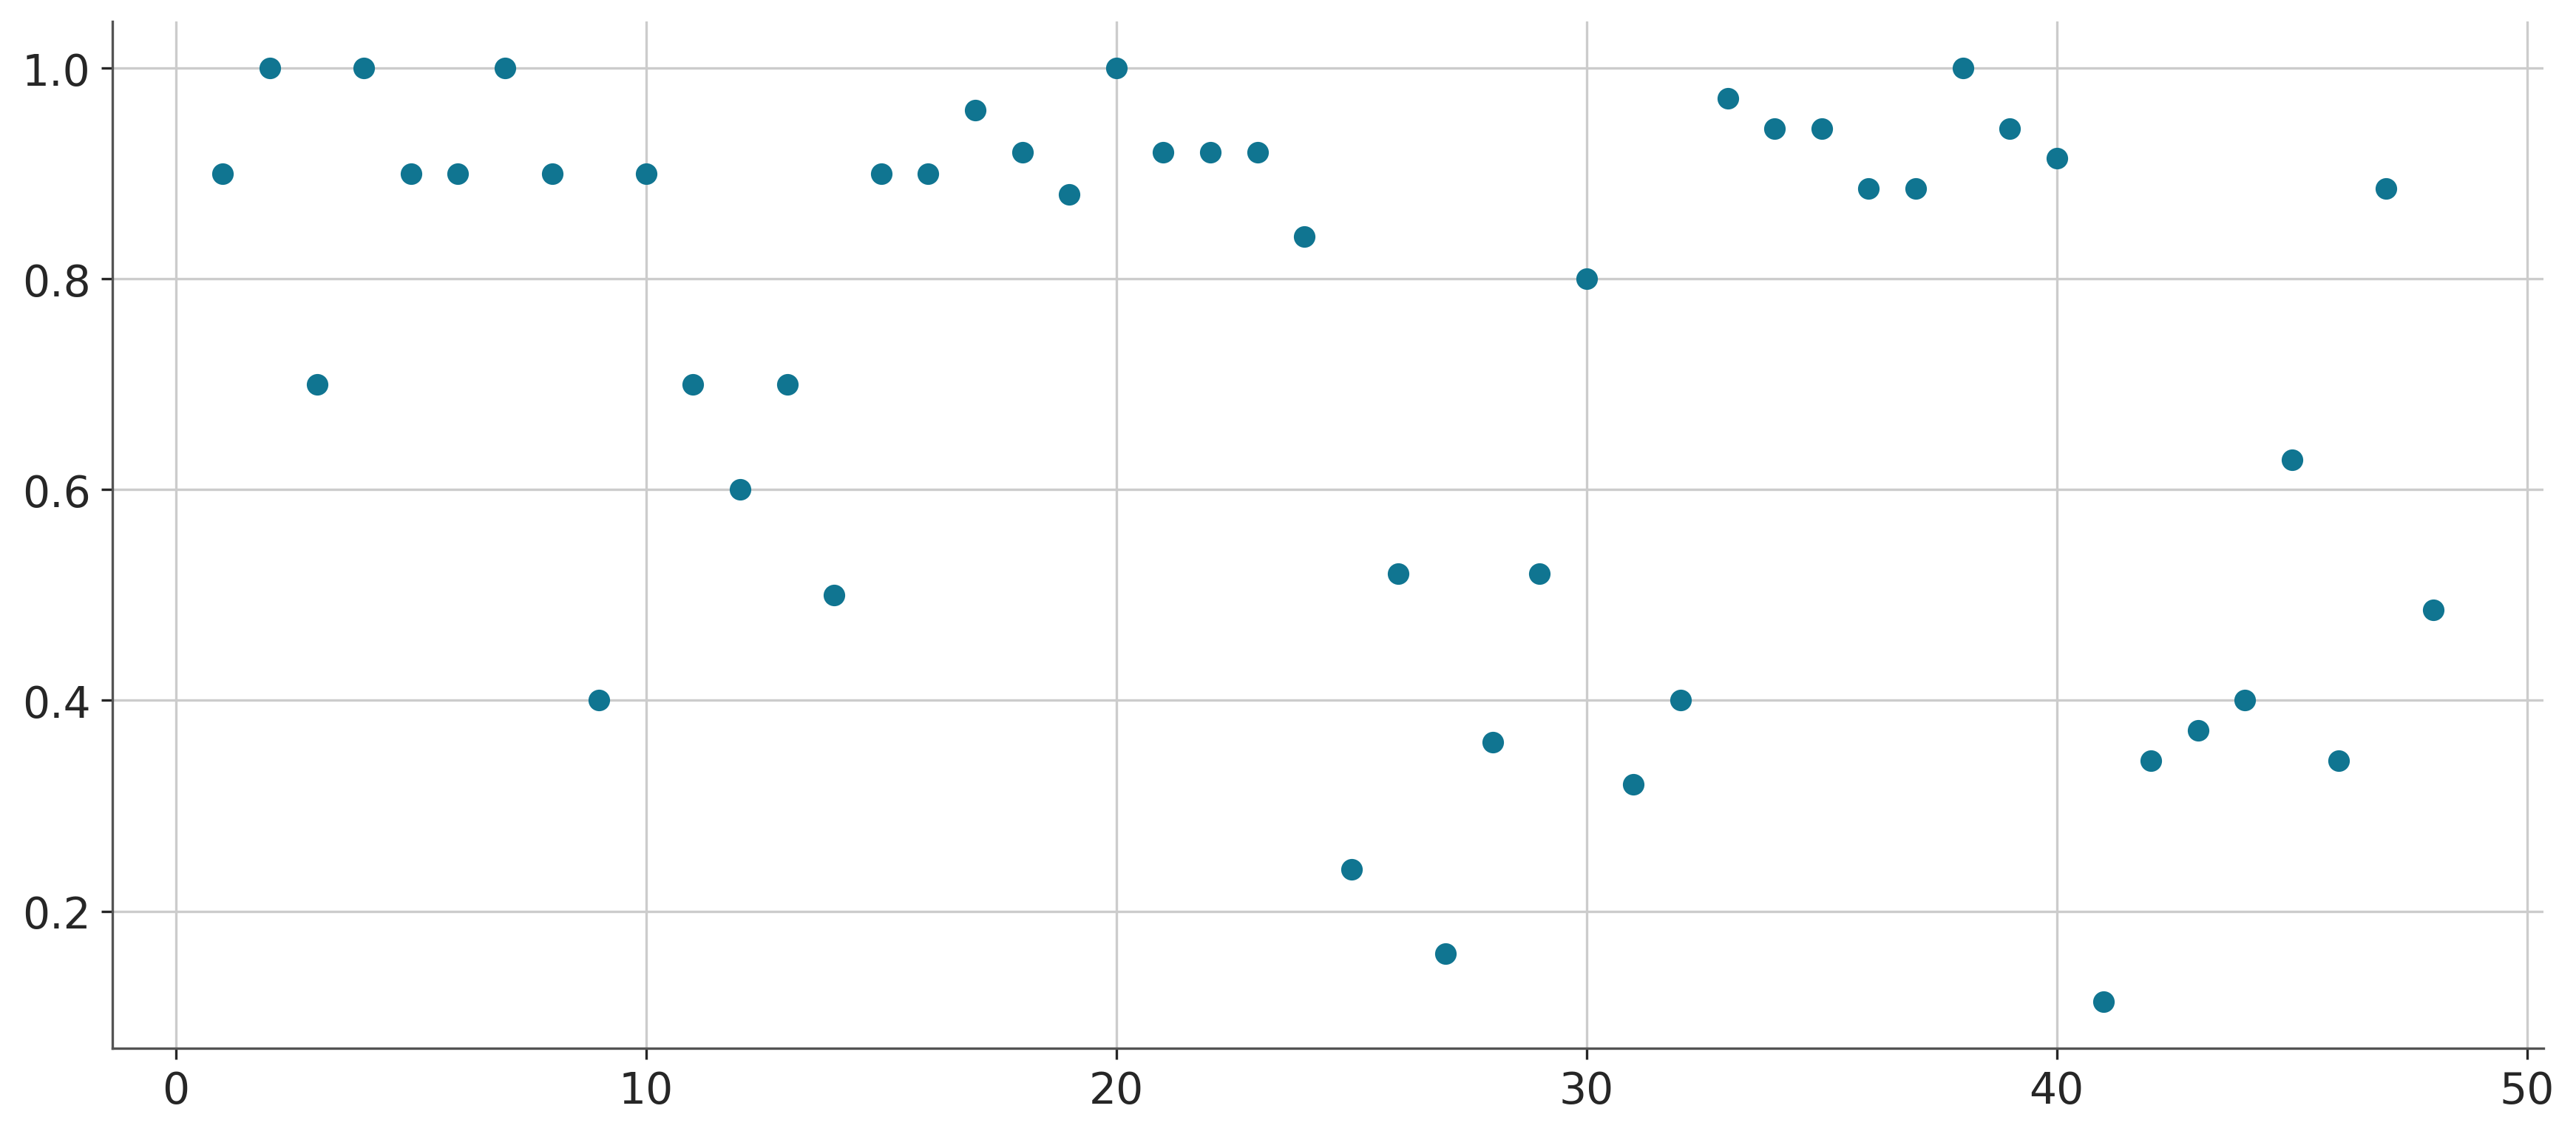

In [101]:
#| code-fold: true 
import matplotlib.pyplot as plt
df.sort_values(by='density')
plt.scatter(x = [i for i in range(1, 49)], y = df['propsurv'])

We will focus on the number surviving (`surv`) out of an intial count (`density`). 

# No pooling 

Math model: 

$$
\begin{align}
\texttt{surv}_i &\sim \text{Binomial}(\texttt{density}_i, p_i) \\ 
\text{logit}(p_i) &= \alpha_{i} \\ 
\alpha_j &\sim \mathcal{N}(0, 1.5), j \in [48]
\end{align}
$$

In [4]:
#| output: false 
# corresponds to R code 13.2
with pm.Model() as model_1:
    # prior 
    alpha = pm.Normal("alpha", 0, 1.5, shape = len(df))
    # link 
    p_survived = pm.Deterministic("p_survived", pm.math.invlogit(alpha))
    # likelihood 
    survived = pm.Binomial("survived", n=df.density, p=p_survived, observed=df.surv)

    model_1_trace = pm.sample()
    model_1_trace = pm.compute_log_likelihood(model_1_trace)
    # posterior predictive check 
    pm.sample_posterior_predictive(model_1_trace, extend_inferencedata=True)


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha]


                                        
                 S…   G…   S…           
  P…   D…   D…   s…   e…   S…   …   R…  
 ────────────────────────────────────── 
  ━━   0    0    0…   0    0…   …   -…  
                           d…           
  ━━   0    0    0…   0    0…   …   -…  
                           d…           
  ━━   0    0    0…   0    0…   …   -…  
                           d…           
  ━━   0    0    0…   0    0…   …   -…  
                           d…           
                                        
                 S…   G…   S…           
  P…   D…   D…   s…   e…   S…   …   R…  
 ────────────────────────────────────── 
  ╸━   5…   0    0…   7    4…   …   0…  
                           d…           
  ╸━   5…   0    0…   7    4…   …   0…  
                           d…           
  ━━   4…   0    0…   7    4…   …   0…  
                           d…           
  ━━   4…   0    0…   7    3…   …   0…  
                           d…           
                

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.


Computing ... ━━━━━━━━━━━━━ 100% 0:00:00:--:--


Sampling: [survived]


Sampling ... ━━━━━━ 100% 0:00:… / 0:00:…0:00:…


In [91]:
# check output 
az.summary(model_1_trace)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha[0],1.721,0.755,0.320,3.100,0.008,0.014,8866.0,2812.0,1.0
alpha[1],2.400,0.894,0.815,4.131,0.011,0.017,7600.0,2746.0,1.0
alpha[2],0.746,0.618,-0.469,1.847,0.007,0.012,8869.0,2820.0,1.0
alpha[3],2.382,0.887,0.795,4.096,0.010,0.019,9025.0,2466.0,1.0
alpha[4],1.737,0.787,0.282,3.234,0.009,0.015,7840.0,2479.0,1.0
...,...,...,...,...,...,...,...,...,...
p_survived[43],0.405,0.079,0.263,0.556,0.001,0.001,8347.0,2943.0,1.0
p_survived[44],0.621,0.080,0.470,0.769,0.001,0.002,9117.0,2699.0,1.0
p_survived[45],0.351,0.078,0.202,0.498,0.001,0.001,8229.0,2453.0,1.0
p_survived[46],0.860,0.055,0.752,0.948,0.001,0.001,7756.0,2918.0,1.0


array([[<Axes: title={'center': 'alpha'}>, <Axes: title={'center': 'alpha'}>],
       [<Axes: title={'center': 'p_survived'}>, <Axes: title={'center': 'p_survived'}>]], dtype=object)

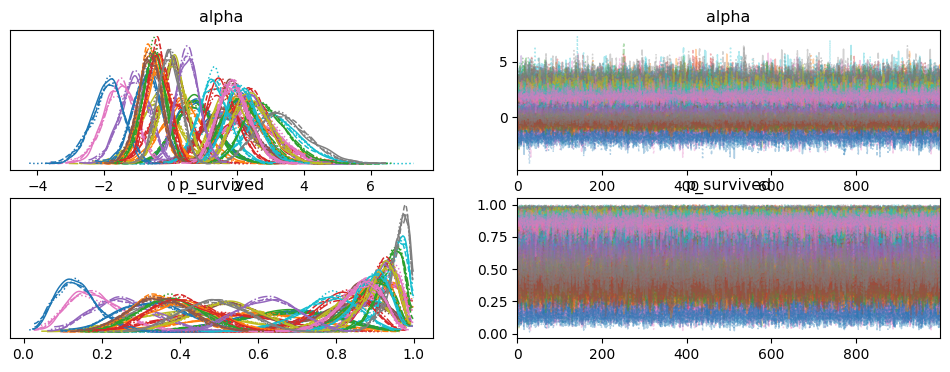

In [6]:
az.plot_trace(model_1_trace)

<Axes: xlabel='survived'>

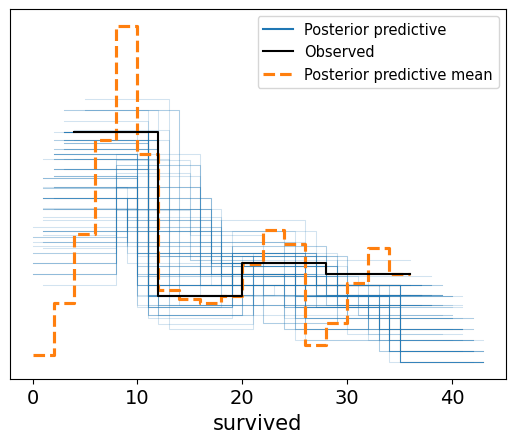

In [7]:
# pp check 
az.plot_ppc(model_1_trace, num_pp_samples=100)

# With pooling 

Math model: 
$$
\begin{align}
\texttt{surv}_i &\sim \text{Binomial}(N_i, p_i) \\ 
\text{logit}(p_i) &\sim \alpha_{\text{TANK}[i]} \\ 
\alpha_j &\sim \mathcal{N}(\bar{\alpha}, \sigma), j \in [48] \\ 
\bar{\alpha} &\sim \mathcal{N}(0, 1.5) \\ 
\sigma &\sim \text{Exponential}(1) 
\end{align}
$$

In [8]:
#| output: false 
# corresponds to R code 13.3
with pm.Model() as model_2:
    # hyperprior 
    sigma = pm.Exponential("sigma", 1)
    alpha_bar = pm.Normal("alpha_bar", 0, 1.5)
    # prior 
    alpha = pm.Normal("alpha", mu=alpha_bar, sigma=sigma, shape=len(df))
    # link 
    p_survived = pm.Deterministic("p_survived", pm.math.invlogit(alpha))
    # likelihood 
    survived = pm.Binomial("survived", n=df.density, p=p_survived, observed=df.surv)

    model_2_trace = pm.sample()
    model_2_trace = pm.compute_log_likelihood(model_2_trace)
    # posterior predictive check 
    pm.sample_posterior_predictive(model_2_trace, extend_inferencedata=True)


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, alpha_bar, alpha]


                                                                                                                                  
  Progress                                   Draws   Divergences   Step size   Grad evals   Sampling Speed   Elapsed   Remaining  
 ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   0       0             0.000       0            0.00 draws/s     0:00:00   -:--:--    
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   0       0             0.000       0            0.00 draws/s     0:00:00   -:--:--    
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   0       0             0.000       0            0.00 draws/s     0:00:00   -:--:--    
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   0       0             0.000       0            0.00 draws/s     0:00:00   -:--:--    
                                                                                   

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.


Computing ... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:00:--:--


Sampling: [survived]


Sampling ... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:00 / 0:00:00:00:00


In [27]:
# check posterior fit 
az.summary(model_2_trace, round_to=2)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha_bar,1.35,0.26,0.88,1.85,0.00,0.00,5063.43,3030.24,1.0
alpha[0],2.13,0.89,0.46,3.78,0.01,0.02,7276.89,2643.59,1.0
alpha[1],3.10,1.12,1.12,5.18,0.02,0.02,5023.20,2541.04,1.0
alpha[2],0.99,0.67,-0.20,2.27,0.01,0.01,7794.92,2864.81,1.0
alpha[3],3.09,1.13,1.09,5.27,0.02,0.02,4801.68,2156.00,1.0
...,...,...,...,...,...,...,...,...,...
p_survived[43],0.42,0.08,0.27,0.57,0.00,0.00,5566.55,2445.12,1.0
p_survived[44],0.64,0.08,0.48,0.78,0.00,0.00,7655.68,2726.25,1.0
p_survived[45],0.36,0.08,0.22,0.51,0.00,0.00,8198.61,2725.24,1.0
p_survived[46],0.88,0.05,0.78,0.97,0.00,0.00,5496.54,2647.30,1.0


array([[<Axes: title={'center': 'alpha_bar'}>,
        <Axes: title={'center': 'alpha_bar'}>],
       [<Axes: title={'center': 'alpha'}>,
        <Axes: title={'center': 'alpha'}>],
       [<Axes: title={'center': 'sigma'}>,
        <Axes: title={'center': 'sigma'}>],
       [<Axes: title={'center': 'p_survived'}>,
        <Axes: title={'center': 'p_survived'}>]], dtype=object)

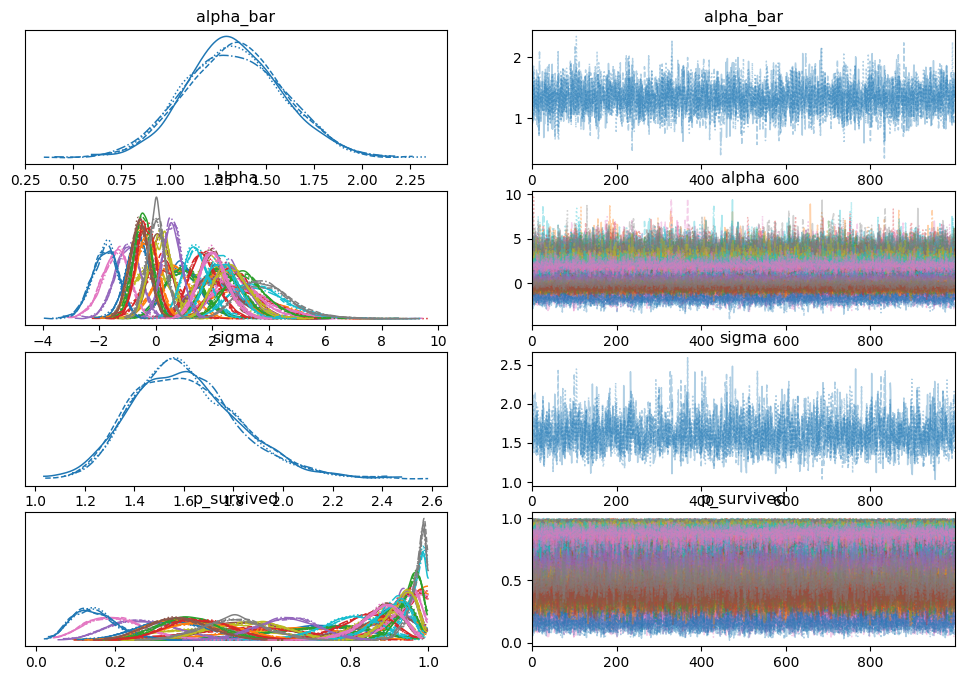

In [46]:
az.plot_trace(model_2_trace)

<Axes: xlabel='survived'>

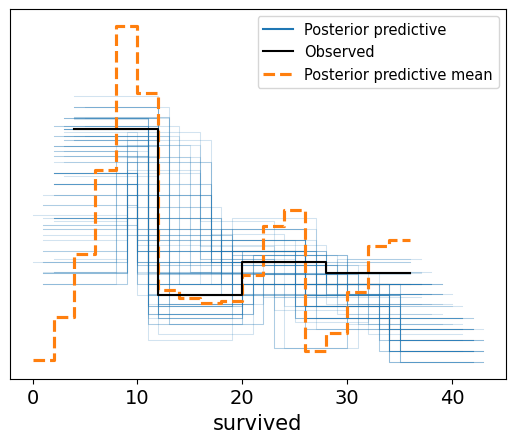

In [9]:
# pp check 
az.plot_ppc(model_2_trace, num_pp_samples=100)

In [ ]:
# TODO -- figure out how to plot ecdf 

# Model comparison 

In [11]:
#| warning: false 
az.compare({'unpooled': model_1_trace, 'pooled': model_2_trace})

/Users/shenglong/Downloads/mika-long.github.io/.venv/lib/python3.13/site-packages/arviz/stats/stats.py:797: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/Users/shenglong/Downloads/mika-long.github.io/.venv/lib/python3.13/site-packages/arviz/stats/stats.py:797: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
pooled,0,-111.604519,32.480297,0.000000,1.0,4.253222,0.00000,True,log
unpooled,1,-120.496778,38.884615,8.892259,0.0,2.424403,2.83376,True,log


Observe that the `pooled` model is better than the `unpooled` model. 

---

# More complex model --- multilevel Chimpanzees 

The tadpole example is "easy" as it does not involve complex grouping, as each row is its own group. Next we will explore the chimpanzee dataset for something a bit more complex to demonstrate the power of the `PyMC` syntax. 

The chimpanzee data is obtained from [here](). The example we're looking at is *13.3.1 Multilevel chimpanzees*. We will create a new column, **treatment**, that is a combination of `prosoc_left` and `condition`. 

Here's the math model: 
$$
\begin{align}
\texttt{pulled\_left}_i &\sim \text{Binomial}(1, p_i) \\ 
\text{logit}(p_i) &= \alpha_{\texttt{actor}[i]} + \gamma_{\texttt{block}[i]} + \beta_{\texttt{treatment}[i]} \\
\beta_j &\sim \mathcal{N}(0, 0.5), j \in [4] \\
\alpha_j &\sim \mathcal{N}(\bar{\alpha}, \sigma_\alpha), j \in [7] \\ 
\gamma_j &\sim \mathcal{N}(0, \sigma_\gamma), j \in [6] \\ 
\bar{\alpha} &\sim \mathcal{N}(0, 1.5) \\ 
\sigma_\alpha &\sim \text{Exponential}(1) \\ 
\sigma_\gamma &\sim \text{Exponential}(1)
\end{align}
$$

In [6]:
# read in the data 
df = pd.read_csv("chimpanzees.csv", delimiter=";")
# create a new treatment column 
df['treatment'] = df['condition'].astype(str) + "_" + df['prosoc_left'].astype(str)
df.info()
df.head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 504 entries, 0 to 503
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   actor         504 non-null    int64  
 1   recipient     252 non-null    float64
 2   condition     504 non-null    int64  
 3   block         504 non-null    int64  
 4   trial         504 non-null    int64  
 5   prosoc_left   504 non-null    int64  
 6   chose_prosoc  504 non-null    int64  
 7   pulled_left   504 non-null    int64  
 8   treatment     504 non-null    object 
dtypes: float64(1), int64(7), object(1)
memory usage: 35.6+ KB


,actor,recipient,condition,block,trial,prosoc_left,chose_prosoc,pulled_left,treatment
0,1,NaN,0,1,2,0,1,0,0_0
1,1,NaN,0,1,4,0,0,1,0_0
2,1,NaN,0,1,6,1,0,0,0_1
3,1,NaN,0,1,8,0,1,0,0_0
4,1,NaN,0,1,10,1,1,1,0_1


## Small tangent on `coord` and `dim`

`PyMC` and `Arviz` utilizes this object called `InferenceData`.^[Here are two really good sources for more reading: [source1](https://cluhmann.github.io/inferencedata/) and [source2](https://oriolabrilpla.cat/en/blog/posts/2022/pymc-arviz.html).] For first-time users, what "coordinate" and "dimension" mean will probably cause some confusion. 

To start, they are both parameters of an `xarray` `DataArray` object: 


In [2]:
import xarray as xr

data = xr.DataArray([[1, 2, 3], [4, 5, 6]], 
    dims=("user", "day"), 
    coords={"user": ['Alice', 'Bob'], 
        "day": ["Mon", "Tue", "Wed"]
    })
data 

<xarray.DataArray (user: 2, day: 3)> Size: 48B
array([[1, 2, 3],
       [4, 5, 6]])
Coordinates:
  * user     (user) <U5 40B 'Alice' 'Bob'
  * day      (day) <U3 36B 'Mon' 'Tue' 'Wed'

In [3]:
data['user']

<xarray.DataArray 'user' (user: 2)> Size: 40B
array(['Alice', 'Bob'], dtype='<U5')
Coordinates:
  * user     (user) <U5 40B 'Alice' 'Bob'

The old method (with `PyMC3`) is to use `pd.factorize` to create a categoricable index column for the actual data column. For example, something like 

```python
sex_idx, sex_codes = pd.factorize(df["sex"])
```

The new method is to define `sex` as a dimension and label it as such. 

In [9]:
coords = {
    'actor': df.actor.unique(), 
    'block': df.block.unique(),
    'treatment': df.treatment.unique(),
}
actor_idx, actor_codes = pd.factorize(df['actor'])
block_idx, block_codes = pd.factorize(df['block'])
treat_idx, treat_codes = pd.factorize(df['treatment'])

In [13]:
# define and fit model 
with pm.Model(coords=coords) as chimp_model:
    # hyperpriors 
    a_bar = pm.Normal("a_bar", 0, 1.5)
    sigma_a = pm.Exponential("sigma_a", 1)
    sigma_gamma = pm.Exponential("sigma_gamma", 1)
    # prior 
    alpha = pm.Normal("alpha", mu=a_bar, sigma=sigma_a, dims="actor")
    gamma = pm.Normal("gamma", mu=0, sigma=sigma_gamma, dims="block")
    beta = pm.Normal("beta", mu=0, sigma=0.5, dims="treatment")
    # link 
    logits = alpha[actor_idx] + gamma[block_idx] + beta[treat_idx] 
    # likelihood 
    obs = pm.Bernoulli("obs", logit_p=logits, observed=df['pulled_left'])

In [14]:
with chimp_model: 
    chimp_model_trace = pm.sample(draws=1000, tune=1000, progressbar=False)
    chimp_model_trace = pm.compute_log_likelihood(chimp_model_trace, progressbar=False)
    # posterior predictive check 
    pm.sample_posterior_predictive(chimp_model_trace, extend_inferencedata=True, progressbar=False)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [a_bar, sigma_a, sigma_gamma, alpha, gamma, beta]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 28 seconds.
There were 37 divergences after tuning. Increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
Sampling: [obs]


The above model will give you a warning about "22 divergences after tuning", which is similar to what the textbook says. For now we will ignore this and proceed to exmaine some of the outputs here: 

In [41]:
az.summary(chimp_model_trace)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
a_bar,0.598,0.764,-0.835,2.057,0.017,0.016,1967.0,1814.0,1.00
alpha[1],-0.340,0.364,-1.054,0.320,0.011,0.006,1144.0,1904.0,1.00
alpha[2],4.750,1.377,2.580,7.257,0.038,0.058,1669.0,1533.0,1.00
alpha[3],-0.646,0.369,-1.369,0.010,0.012,0.006,1022.0,1674.0,1.00
alpha[4],-0.647,0.367,-1.343,0.044,0.012,0.006,1016.0,1991.0,1.00
alpha[5],-0.339,0.362,-1.034,0.316,0.012,0.006,936.0,1930.0,1.00
alpha[6],0.599,0.368,-0.091,1.292,0.012,0.006,932.0,1861.0,1.00
alpha[7],2.134,0.463,1.321,3.009,0.013,0.007,1263.0,1845.0,1.00
gamma[1],-0.185,0.224,-0.612,0.167,0.006,0.007,1506.0,1752.0,1.00
gamma[2],0.039,0.192,-0.314,0.417,0.004,0.006,2188.0,1945.0,1.00


array([<Axes: title={'center': '89.0% HDI'}>], dtype=object)

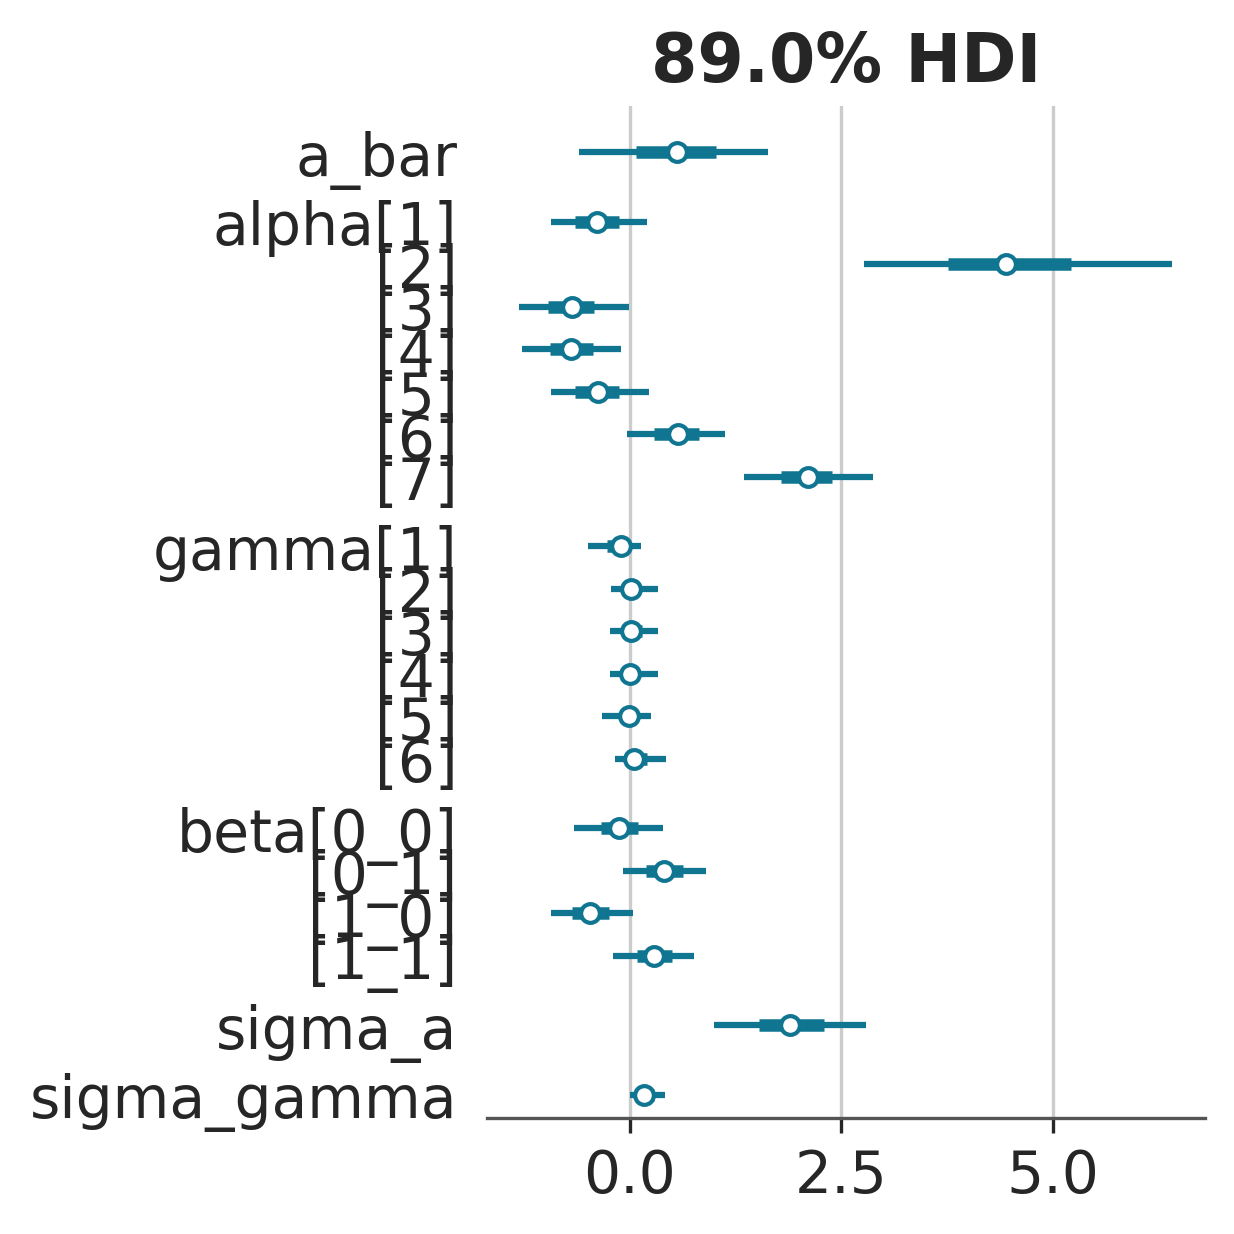

In [108]:
#| code-fold: true 
az.plot_forest(chimp_model_trace, figsize=(4,4), combined=True, hdi_prob=0.89)

In [15]:
# look at posterior 
chimp_model_trace.posterior

<xarray.Dataset> Size: 648kB
Dimensions:      (chain: 4, draw: 1000, actor: 7, block: 6, treatment: 4)
Coordinates:
  * chain        (chain) int64 32B 0 1 2 3
  * draw         (draw) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
  * actor        (actor) int64 56B 1 2 3 4 5 6 7
  * block        (block) int64 48B 1 2 3 4 5 6
  * treatment    (treatment) <U3 48B '0_0' '0_1' '1_0' '1_1'
Data variables:
    a_bar        (chain, draw) float64 32kB 1.517 0.1372 ... 0.8726 0.4252
    alpha        (chain, draw, actor) float64 224kB -0.04143 4.609 ... 1.79
    gamma        (chain, draw, block) float64 192kB -0.06185 0.03275 ... 0.0268
    beta         (chain, draw, treatment) float64 128kB 0.0411 0.3425 ... 0.2763
    sigma_a      (chain, draw) float64 32kB 1.497 1.873 1.327 ... 1.751 1.537
    sigma_gamma  (chain, draw) float64 32kB 0.0758 0.05949 ... 0.1035 0.04444
Attributes:
    created_at:                 2025-12-17T23:54:12.951912+00:00
    arviz_version:              0.22.0
    inference_library:          pymc
    inference_library_version:  5.26.1
    sampling_time:              27.502137184143066
    tuning_steps:               1000

### Dealing with divergent transitions 

The first trick is to increase the target acceptance rate. In `stan` related code, this is done by pushing `adapt_delta = 0.95` to `adapt_delta=0.99`. 

In [81]:
with chimp_model: 
    chimp_model_trace = pm.sample(progressbar=False, target_accept=0.99)
    # chimp_model_trace = pm.compute_log_likelihood(chimp_model_trace)
    # posterior predictive check 
    # pm.sample_posterior_predictive(chimp_model_trace, extend_inferencedata=True)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [a_bar, sigma_a, sigma_gamma, alpha, gamma, beta]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 8 seconds.
There were 78 divergences after tuning. Increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


This doesn't seem to solve our problem, so we will turn to the second trick: **reparameterization**. 

In [82]:
# R code 13.29 
# define and fit model 
with pm.Model() as chimp_model_2:
    chimp_model_2.add_coord("actors", actors)
    chimp_model_2.add_coord("blocks", blocks)
    chimp_model_2.add_coord("treatments", treatments)
    # hyperpriors 
    a_bar = pm.Normal("a_bar", 0, 1.5)
    sigma_a = pm.Exponential("sigma_a", 1)
    sigma_gamma = pm.Exponential("sigma_gamma", 1)
    # prior 
    z = pm.Normal("z", mu=0, sigma=1, dims="actors")
    x = pm.Normal("x", mu=0, sigma=1, dims="blocks")
    beta = pm.Normal("beta", mu=0, sigma=0.5, dims="treatments")
    # link 
    logits = a_bar + z[actor_idx] * sigma_a + x[block_idx] * sigma_gamma + beta[treat_idx] 
    # likelihood 
    obs = pm.Bernoulli("obs", logit_p=logits, observed=df['pulled_left'])


In [83]:
with chimp_model_2: 
    chimp_model_2_trace = pm.sample(draws=1000, tune=1000, progressbar=False)
    chimp_model_2_trace = pm.compute_log_likelihood(chimp_model_2_trace)
    # posterior predictive check 
    pm.sample_posterior_predictive(chimp_model_2_trace, extend_inferencedata=True)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [a_bar, sigma_a, sigma_gamma, z, x, beta]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 3 seconds.


Computing ... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:00:--:--


Sampling: [obs]


Sampling ... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:00 / 0:00:00━━━━━━━━━━━━━━  50% 0:00:01 / 0:00:00


No divergent transitions! 

In [84]:
az.summary(chimp_model_2_trace)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
a_bar,0.601,0.715,-0.685,2.010,0.022,0.018,1114.0,1269.0,1.0
z[1],-0.505,0.376,-1.231,0.173,0.011,0.007,1261.0,2055.0,1.0
z[2],2.118,0.659,0.947,3.357,0.015,0.010,1853.0,2265.0,1.0
z[3],-0.671,0.390,-1.401,0.060,0.011,0.007,1207.0,1608.0,1.0
z[4],-0.667,0.389,-1.415,0.017,0.011,0.006,1204.0,1867.0,1.0
z[5],-0.511,0.373,-1.184,0.205,0.011,0.006,1218.0,1828.0,1.0
z[6],-0.007,0.354,-0.632,0.685,0.010,0.006,1277.0,1956.0,1.0
z[7],0.809,0.462,-0.019,1.713,0.012,0.009,1450.0,1409.0,1.0
x[1],-0.647,0.872,-2.348,0.954,0.015,0.015,3455.0,3043.0,1.0
x[2],0.146,0.859,-1.548,1.737,0.014,0.016,3701.0,2187.0,1.0


<Axes: xlabel='obs'>

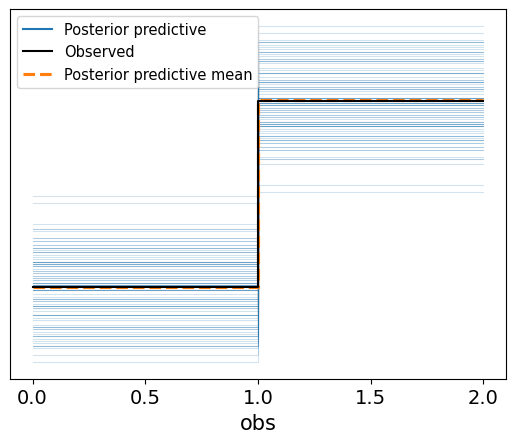

In [87]:
az.plot_ppc(chimp_model_2_trace, num_pp_samples=100)

array([<Axes: title={'center': '89.0% HDI'}>], dtype=object)

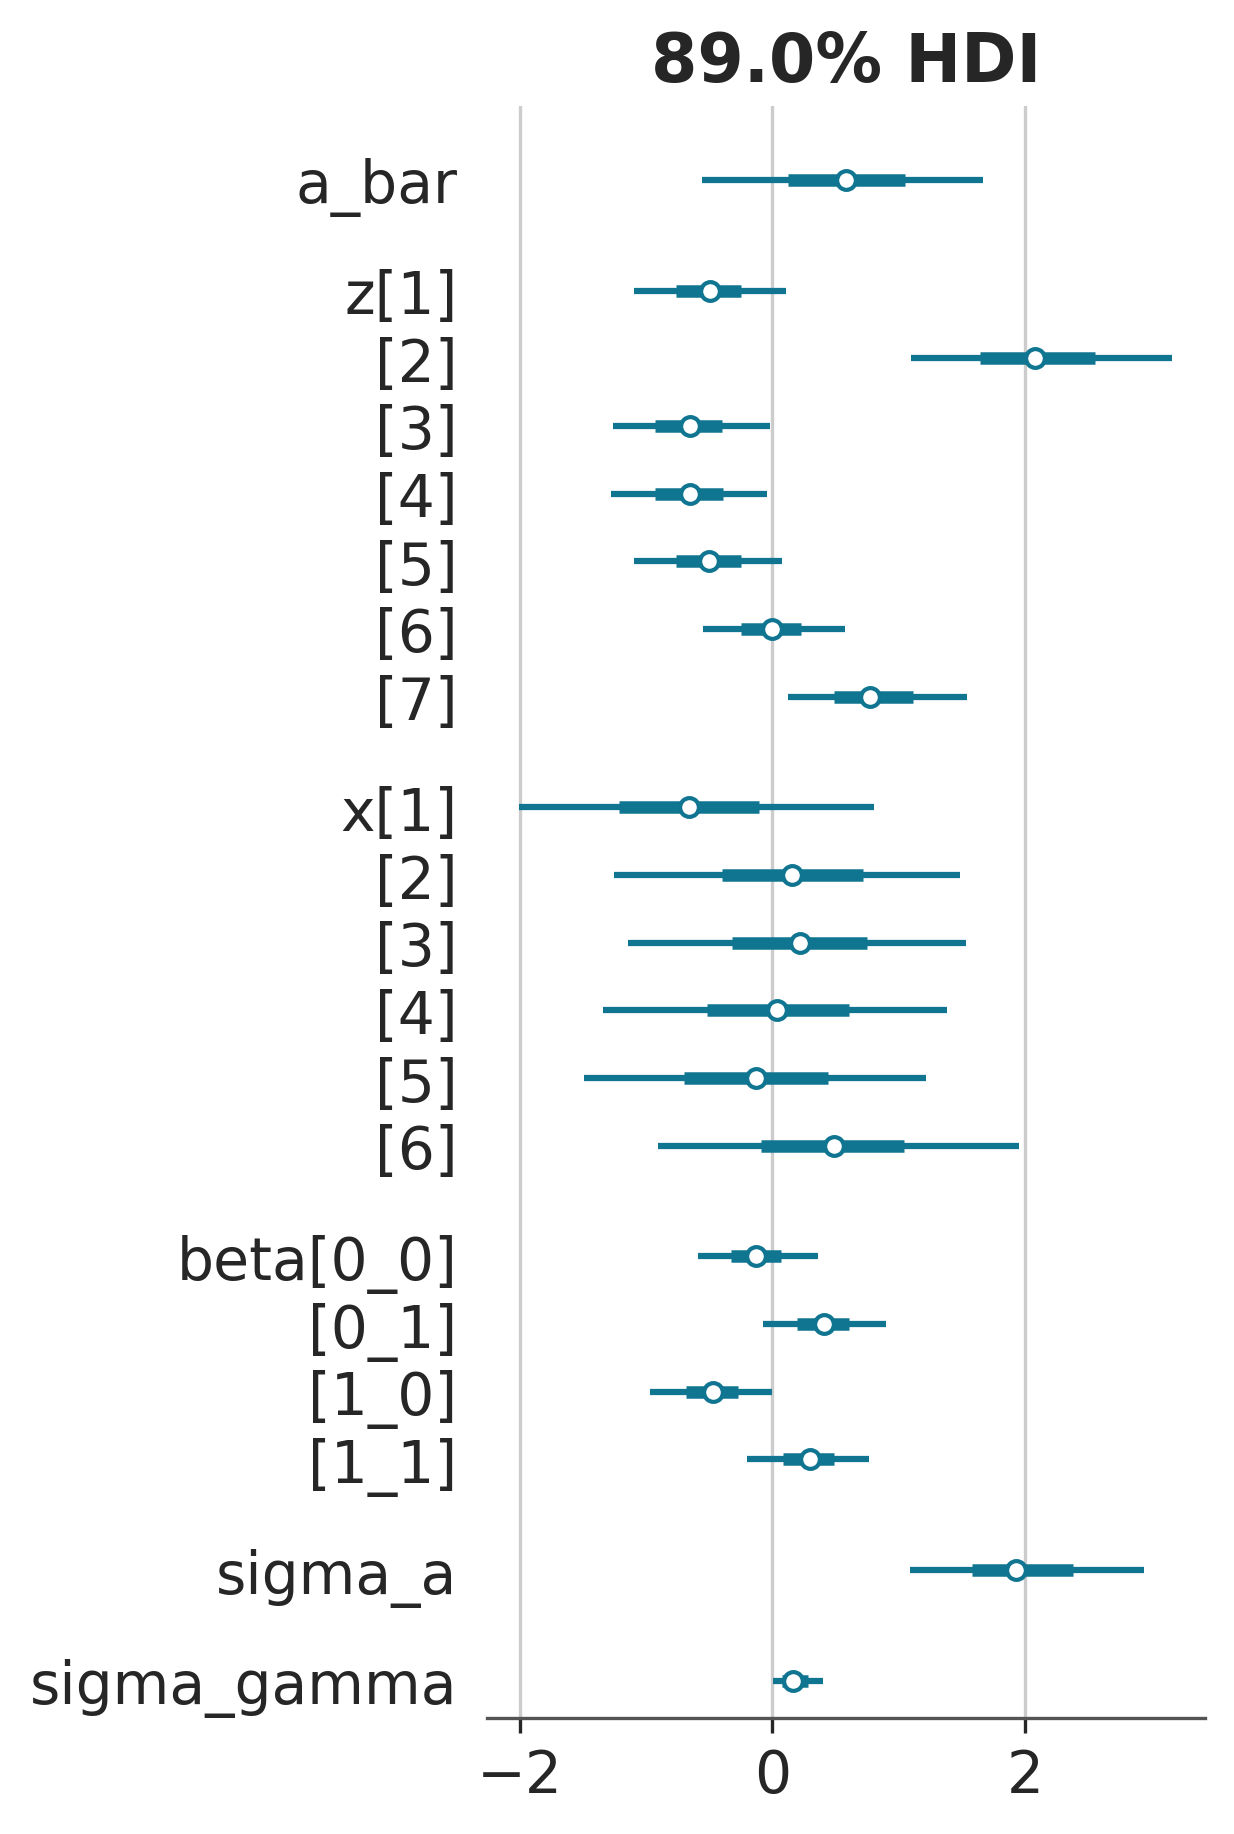

In [ ]:
#| code-fold: true 
az.plot_forest(chimp_model_2_trace, figsize=(4,6), combined=True, hdi_prob=0.89)